## 📓 Notebook 02: KFold vs. Stratified KFold

**Skills practiced:** `KFold`, `StratifiedKFold`, per-fold scoring, `np.std`, plotting per-fold class proportions.

**Goal:** Show with real numbers that stratified folds give more stable scores than plain folds on an imbalanced target.

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [109]:
x=pd.read_csv('../data/processed/x.csv')
y=pd.read_csv('../data/processed/y.csv').squeeze()

In [110]:
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 45 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   SeniorCitizen                            7043 non-null   int64  
 1   tenure                                   7043 non-null   int64  
 2   MonthlyCharges                           7043 non-null   float64
 3   TotalCharges                             7043 non-null   float64
 4   gender_Female                            7043 non-null   float64
 5   gender_Male                              7043 non-null   float64
 6   Partner_No                               7043 non-null   float64
 7   Partner_Yes                              7043 non-null   float64
 8   Dependents_No                            7043 non-null   float64
 9   Dependents_Yes                           7043 non-null   float64
 10  PhoneService_No                          7043 non-null   fl

In [111]:
y.value_counts(normalize=True)

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

In [112]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []
for train_index, valid_index in kf.split(x):
    m=LogisticRegression(max_iter=1000)
    m.fit(x.iloc[train_index], y.iloc[train_index])
    proba=m.predict_proba(x.iloc[valid_index])[:,1]
    roc_auc = roc_auc_score(y.iloc[valid_index], proba)
    results.append(roc_auc)
    print(f'Fold AUC: {roc_auc:.4f}')
print(f'Standard Deviation of AUC: {np.std(results):.4f}')
print(f'Mean AUC: {np.mean(results):.4f}')

c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold AUC: 0.8623
Fold AUC: 0.8638


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold AUC: 0.8292


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold AUC: 0.8335
Fold AUC: 0.8425
Standard Deviation of AUC: 0.0144
Mean AUC: 0.8463


In [113]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for train_index, valid_index in skf.split(x,y):
    m2=LogisticRegression(max_iter=1000)
    m2.fit(x.iloc[train_index], y.iloc[train_index])
    proba=m2.predict_proba(x.iloc[valid_index])[:,1]
    roc_auc = roc_auc_score(y.iloc[valid_index], proba)
    results.append(roc_auc)
    print(f'Fold AUC: {roc_auc:.4f}')
print(f'Standard Deviation of AUC: {np.std(results):.4f}')
print(f'Mean AUC: {np.mean(results):.4f}')

Fold AUC: 0.8546


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold AUC: 0.8455


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold AUC: 0.8635


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold AUC: 0.8252
Fold AUC: 0.8365
Standard Deviation of AUC: 0.0134
Mean AUC: 0.8451


c:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [114]:
kf_props = [y.iloc[val].mean() for _, val in kf.split(x)]
skf_props = [y.iloc[val].mean() for _, val in skf.split(x, y)]

In [115]:
print(np.shape(kf_props))
print(type(y))

(5,)
<class 'pandas.Series'>


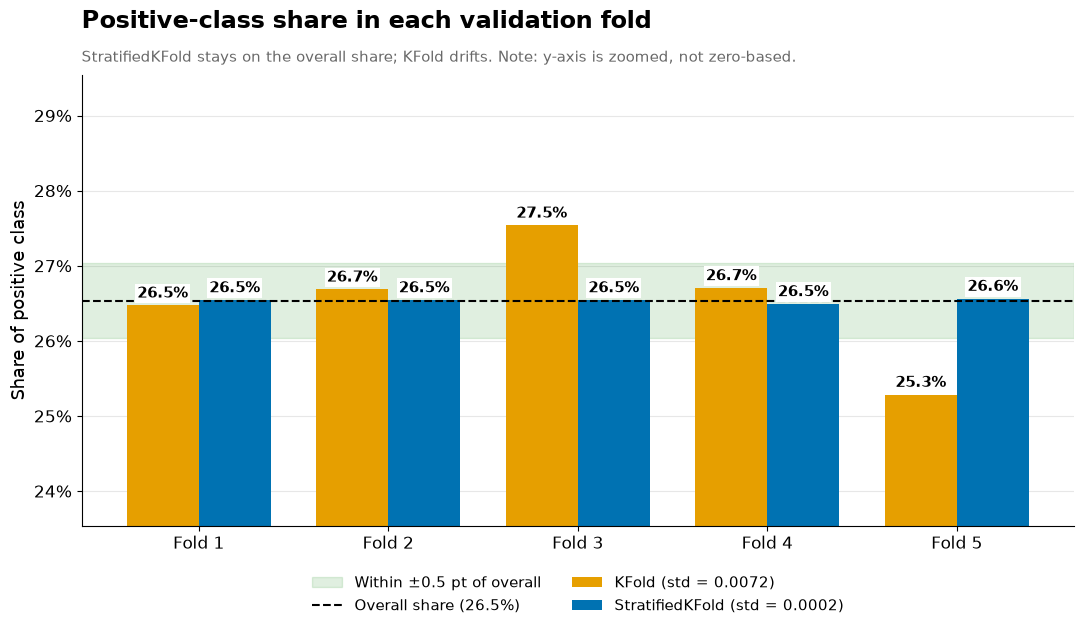

In [116]:
overall = float(y.mean())
plt.rcParams.update({"font.size": 12})
folds = np.arange(1, 6)
bar_w = 0.38
label_box = dict(facecolor="white", edgecolor="none", pad=1.5)

fig, ax = plt.subplots(figsize=(11, 6.5))

ax.axhspan(overall - 0.005, overall + 0.005, color="green", alpha=0.12,
           label="Within ±0.5 pt of overall")
b1 = ax.bar(folds - bar_w / 2, kf_props, width=bar_w, color="#E69F00",
            label=f"KFold (std = {np.std(kf_props):.4f})")
b2 = ax.bar(folds + bar_w / 2, skf_props, width=bar_w, color="#0072B2",
            label=f"StratifiedKFold (std = {np.std(skf_props):.4f})")
ax.axhline(overall, color="black", linestyle="--", linewidth=1.5,
           label=f"Overall share ({overall:.1%})")

ax.bar_label(b1, labels=[f"{v:.1%}" for v in kf_props], padding=3,
             fontsize=11, fontweight="bold", bbox=label_box)
ax.bar_label(b2, labels=[f"{v:.1%}" for v in skf_props], padding=3,
             fontsize=11, fontweight="bold", bbox=label_box)

ax.set_ylim(overall - 0.03, overall + 0.03)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xticks(folds)
ax.set_xticklabels([f"Fold {i}" for i in folds], fontsize=12)
ax.set_ylabel("Share of positive class", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

ax.set_title("Positive-class share in each validation fold",
             loc="left", fontsize=17, fontweight="bold", pad=34)
ax.text(0, 1.03, "StratifiedKFold stays on the overall share; KFold drifts. "
        "Note: y-axis is zoomed, not zero-based.",
        transform=ax.transAxes, fontsize=11, color="dimgray")

ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08),
          ncol=2, fontsize=11)

fig.tight_layout()
fig.savefig("../outputs/figures/fold_balance.png", dpi=200, bbox_inches="tight")
plt.show()

In [117]:
print("KFold std:", np.std(kf_props))
print("Stratified std:", np.std(skf_props))

KFold std: 0.007245123770155327
Stratified std: 0.0002389625185129935
